In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
fake = pd.read_csv('/content/Fake.csv')
real = pd.read_csv('/content/True.csv')

print("Fake News Dataset:")
display(fake.head())

print("Real News Dataset:")
display(real.head())

Fake News Dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


Real News Dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [3]:
fake['label'] = 0
real['label'] = 1

print("Fake news label: 0")
print("Real news label: 1")

Fake news label: 0
Real news label: 1


In [4]:
data = pd.concat([fake, real], axis=0)

data = data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Total dataset shape:", data.shape)
display(data.head())

Total dataset shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [5]:
data = data.dropna(subset=['text'])

data['content'] = data['title'].fillna('') + " " + data['text']

data = data[['content', 'label']]

print("Missing values:")
print(data.isnull().sum())

print("Cleaned dataset:")
display(data.head())

Missing values:
content    0
label      0
dtype: int64
Cleaned dataset:


,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,1


In [6]:
X = data['content']
y = data['label']

print("Input data:", X.shape)
print("Output data:", y.shape)

Input data: (44898,)
Output data: (44898,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (35918,)
Testing data: (8980,)


In [8]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.7
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training shape: (35918, 111555)
Testing shape: (8980, 111555)


In [9]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [10]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 98.56347438752783 %


In [11]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Fake News', 'Real News']
))

              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      4696
   Real News       0.98      0.99      0.98      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



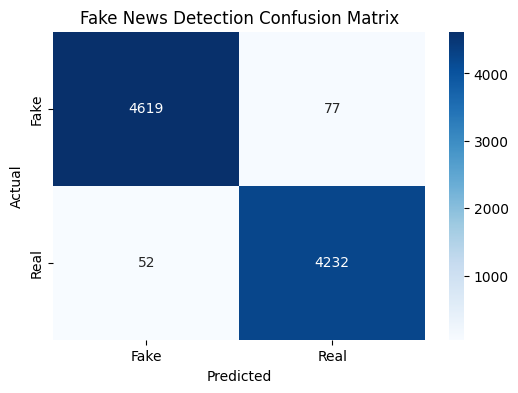

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fake', 'Real'],
    yticklabels=['Fake', 'Real']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Fake News Detection Confusion Matrix')

plt.show()

In [13]:
def predict_news(news):
    news_tfidf = tfidf.transform([news])
    prediction = model.predict(news_tfidf)[0]

    if prediction == 0:
        print("Prediction: FAKE NEWS")
    else:
        print("Prediction: REAL NEWS")


news = input("Enter news text: ")

predict_news(news)

Enter news text: headline
Prediction: FAKE NEWS


In [14]:
import pickle

with open('fake_news_model.pkl', 'wb') as f:
    pickle.dump(model, f)

with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [15]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
matplotlib
seaborn
jupyter

Writing requirements.txt


In [16]:
%%writefile README.md
# Fake News Detection Using Machine Learning

## Project Description
This project uses Machine Learning and Natural Language Processing to classify news articles as Fake or Real.

## Problem Statement
Fake news spreads rapidly through online platforms and can mislead people. This project aims to automatically classify news articles using machine learning.

## Objectives
- Detect fake and real news.
- Preprocess news text.
- Apply TF-IDF vectorization.
- Train a Logistic Regression model.
- Evaluate model performance.
- Predict news categories.

## Dataset
Fake and Real News Dataset from Kaggle.

https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset

Dataset files:
- Fake.csv
- True.csv

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

## Algorithm
- TF-IDF Vectorization
- Logistic Regression

## Project Workflow
1. Dataset collection
2. Data preprocessing
3. TF-IDF feature extraction
4. Training and testing
5. Model evaluation
6. News prediction

## Results
Add actual accuracy, precision, recall, F1-score and confusion matrix after running the notebook.

## How to Run
Install dependencies:

pip install -r requirements.txt

Run the notebook Fake_News_Detection.ipynb using Google Colab.

## Conclusion
The project demonstrates how machine learning can classify news articles as Fake or Real based on textual patterns.

## Team Members
- Member 1: M.GOUTHAMI(25RBCSE0002)
- Member 2: K.MAHESHWARI(25RBAID0004)
- Member 3: J.MANASA(25RBAIM0063)
- Member 4: C,NEHASRI(25RBAIM0062)

Writing README.md
